In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gebtaero_jax as gx

I11 = 0.1
cs = gx.CrossSection.from_isotropic(EI2=2e4, EI3=4e6, GJ=1e4).with_mass(mu=0.75, i22=1e-3 * I11, i33=I11)
frame = gx.Frame.from_axis([0, 1, 0], twist=0.0)
section = gx.WingSection(chord=1.0, a=0.0, length=16.0, cross_section=cs, frame=frame, n_elements=20)
wing = gx.Wing.from_sections([section], name="Patil")
print(f"weight = {float(wing.weight):.1f} N, surface = {float(wing.surface):.1f} m²")

weight = 117.7 N, surface = 16.0 m²


## Structural modes (no air)
The mixed formulation (Hodges 2003) is linearised about the undeformed state; `K = ∂R/∂x` and `M = ∂R/∂ẋ`
come from `jax.jacfwd`. Reference values from GEBTAero's test suite: 0.357, 2.257, 4.941, 5.048, 6.428 Hz.

In [2]:
model0 = wing.discretize(aero=gx.Aero.NONE)
modes = gx.modal_analysis(model0, gx.FlightCondition())
print("frequencies (Hz):", np.round(modes.table(6)[:, 1], 4))

frequencies (Hz): [ 0.3572  2.2585  4.9411  5.046   6.4279 12.9197]


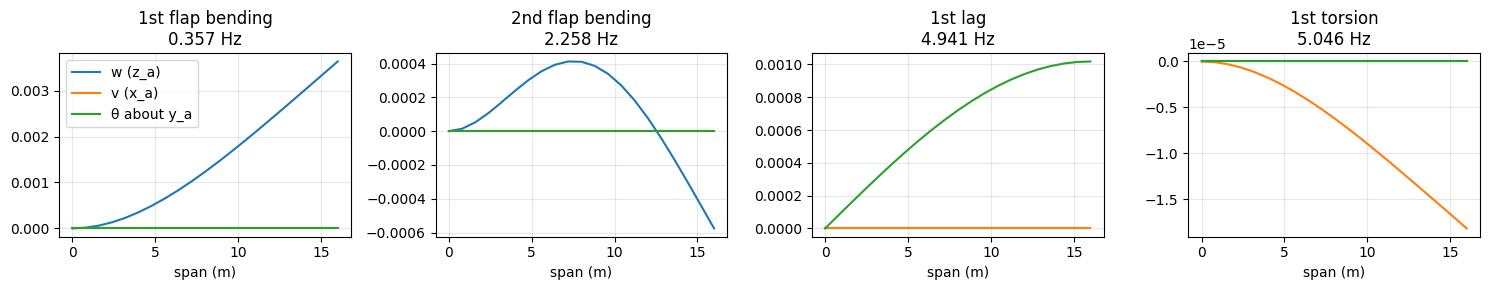

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3), sharey=False)
y = np.asarray(gx.node_positions(model0))[:, 1]
names = ["1st flap bending", "2nd flap bending", "1st lag", "1st torsion"]
for ax, k, name in zip(axs, modes.oscillatory()[:4], names):
    u, th = gx.mode_shape(model0, modes.right[:, k])
    ax.plot(y, u[:, 2], label="w (z_a)")
    ax.plot(y, u[:, 0], label="v (x_a)")
    ax.plot(y, th[:, 1], label="θ about y_a")
    ax.set_title(f"{name}\n{modes.freq_hz[k]:.3f} Hz"); ax.set_xlabel("span (m)"); ax.grid(alpha=.3)
axs[0].legend(); plt.tight_layout()

## V-g / V-f diagram with Peters' unsteady aerodynamics
Modes are tracked across velocities with a MAC-based assignment (GEBTAero's `EigenTabSorted`).
Lag bending is made rigid (EI3 = 0) as in GEBTAero's flutter tests.

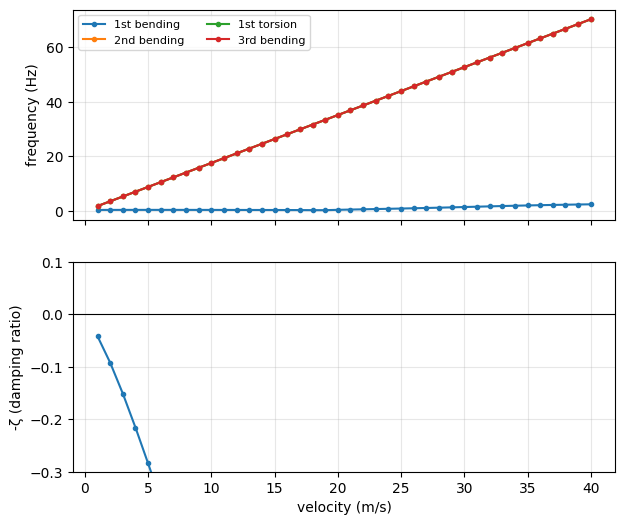

In [4]:
cs_f = gx.CrossSection.from_isotropic(2e4, 0.0, 1e4).with_mass(0.75, 1e-3 * I11, I11)
model = gx.straight_wing(cs_f, span=16.0, chord=1.0, a=0.0, n_elements=10, aero=gx.Aero.PETERS)
flight = gx.FlightCondition(rho=0.0889)
sweep = gx.mode_sweep(model, flight, np.linspace(1.0, 40.0, 40), n_modes=4)
gx.plotting.plot_vg(sweep, labels=["1st bending", "2nd bending", "1st torsion", "3rd bending"], ylim_damping=(-0.3, 0.1));

In [5]:
crit = gx.critical_speeds(model, flight, v_min=1.0, v_max=50.0, n_grid=25)
print(crit["flutter"], "   (GEBTAero: 32.12 m/s, Patil et al.: 32.21 m/s, 22.61 rad/s)")
print(crit["divergence"], "  (GEBTAero: 37.25 m/s, Patil et al.: 37.29 m/s)")
print(f"flutter frequency = {2*np.pi*crit['flutter'].frequency_hz:.2f} rad/s")

CriticalPoint(flutter: V=32.1513 m/s, f=3.5952 Hz)    (GEBTAero: 32.12 m/s, Patil et al.: 32.21 m/s, 22.61 rad/s)
CriticalPoint(divergence: V=37.2305 m/s, f=0.0000 Hz)   (GEBTAero: 37.25 m/s, Patil et al.: 37.29 m/s)
flutter frequency = 22.59 rad/s


## Effect of the aerodynamic model
GEBTAero's three models plus Aeroelasticity.jl's Wagner model (all share `gebtaero_jax.aerodynamics`).

With the CG on the elastic axis (ν = 0) both quasi-steady models predict a weak *single-degree-of-freedom torsional
instability* starting at V → 0 (Re(s) grows like V³) — a known shortcoming of quasi-steady theory that the
unsteady models do not share:

In [6]:
for aero in [gx.Aero.QUASI_STEADY, gx.Aero.QUASI_STEADY_ADDED_MASS]:
    m = gx.straight_wing(cs_f, 16.0, 1.0, 0.0, 10, aero=aero)
    r = gx.modal_analysis(m, flight.replace(velocity=1.0))
    j = r.oscillatory()[np.argmax(r.eigvals.real[r.oscillatory()])]
    print(f"{aero.name:<26s} at 1 m/s: Re(s) = {r.eigvals.real[j]:.2e} 1/s on the {r.freq_hz[j]:.2f} Hz torsion mode")

QUASI_STEADY               at 1 m/s: Re(s) = 1.23e-04 1/s on the 4.95 Hz torsion mode


QUASI_STEADY_ADDED_MASS    at 1 m/s: Re(s) = 1.03e-04 1/s on the 4.89 Hz torsion mode


GEBTAero's test suite therefore compares the models with the CG moved forward (ν = −0.1 m); references: 14.83 m/s (quasi-steady) and 25.85 m/s (quasi-steady with apparent mass).

In [7]:
cs_n = gx.CrossSection.from_isotropic(2e4, 0.0, 1e4).with_mass(0.75, 1e-3 * I11, I11, nu=-0.1)
refs = {gx.Aero.QUASI_STEADY: 14.83, gx.Aero.QUASI_STEADY_ADDED_MASS: 25.85, gx.Aero.WAGNER: None, gx.Aero.PETERS: None}
for aero, ref in refs.items():
    p = gx.flutter_speed(gx.straight_wing(cs_n, 16.0, 1.0, 0.0, 10, aero=aero), flight, 1.0, 50.0, n_grid=25)
    print(f"{aero.name:<26s} V_f = {p.velocity:7.3f} m/s   f = {p.frequency_hz:.3f} Hz   GEBTAero: {ref}")

QUASI_STEADY               V_f =  14.830 m/s   f = 4.941 Hz   GEBTAero: 14.83


QUASI_STEADY_ADDED_MASS    V_f =  25.809 m/s   f = 4.487 Hz   GEBTAero: 25.85


WAGNER                     V_f =  43.871 m/s   f = 3.500 Hz   GEBTAero: None


PETERS                     V_f =  43.910 m/s   f = 3.532 Hz   GEBTAero: None
